# 04 · E2 (ajuste fino) y E3 (segunda arquitectura)
**Entrega 2 · días 8–10.** Necesita GPU y que E1 ya esté ejecutado. Las hipótesis de E2 y E3 deben estar escritas antes.

In [1]:
# PREPARACIÓN (igual en todos los notebooks): conecta Drive, entra a la carpeta del proyecto y deja listos los datos.
from google.colab import drive
drive.mount('/content/drive')

PROYECTO = '/content/drive/MyDrive/yuca-comparacion-final/yuca-comparacion'   # carpeta del proyecto dentro de su Google Drive

import os, sys
os.chdir(PROYECTO)
sys.path.insert(0, PROYECTO)

from src.datos import descargar_dataset
# El .zip se guarda una sola vez en Drive; las fotos se descomprimen en el disco de Colab (más rápido).
RAIZ = str(descargar_dataset(destino='/content/datos', carpeta_zip=PROYECTO + '/data'))
os.environ['YUCA_DATOS'] = RAIZ
print('Proyecto:', os.getcwd())
print('Datos   :', RAIZ)

Mounted at /content/drive
[1/2] Ya existe el archivo /content/drive/MyDrive/yuca-comparacion-final/yuca-comparacion/data/cassavaleafdata.zip; no se descarga de nuevo.
[2/2] Descomprimiendo...
[ok] Dataset listo en: /content/datos/cassavaleafdata
Proyecto: /content/drive/MyDrive/yuca-comparacion-final/yuca-comparacion
Datos   : /content/datos/cassavaleafdata


In [2]:
import torch
print('GPU disponible:', torch.cuda.is_available())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'SIN GPU: menú Entorno de ejecución > Cambiar tipo de entorno > T4 GPU')

GPU disponible: True
Tesla T4


## E3 · Backbone B congelado
Mismo procedimiento, mismas épocas y misma tasa de aprendizaje que E1; solo cambia la arquitectura.
**Comparación primaria: E1 frente a E3.**

In [3]:
from src.entrenar import ejecutar
from IPython.display import Image as Mostrar, display
import pandas as pd
m3 = ejecutar('E3')

[2026-11-18 04:28:19] === E3: Backbone B congelado, solo cabeza ===
[2026-11-18 04:28:19] Dispositivo: Tesla T4 | semilla: 42
[2026-11-18 04:28:21] Imágenes: train=5600 val=1877 test=1885
Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 164MB/s]


[2026-11-18 04:28:22] Parámetros: 2,230,277 totales, 6,405 entrenables, 9.06 MB
[2026-11-18 04:29:18] Época  1/10 | train pérdida 1.0892 F1 0.5146 | val pérdida 0.9216 F1 0.5868 acc 0.6494  <- mejor hasta ahora (guardado)
[2026-11-18 04:30:10] Época  2/10 | train pérdida 0.8542 F1 0.6211 | val pérdida 0.7743 F1 0.6287 acc 0.7144  <- mejor hasta ahora (guardado)
[2026-11-18 04:31:04] Época  3/10 | train pérdida 0.8034 F1 0.6441 | val pérdida 0.7533 F1 0.6783 acc 0.7357  <- mejor hasta ahora (guardado)
[2026-11-18 04:31:55] Época  4/10 | train pérdida 0.7585 F1 0.6637 | val pérdida 0.7570 F1 0.6429 acc 0.7171
[2026-11-18 04:32:48] Época  5/10 | train pérdida 0.7446 F1 0.6675 | val pérdida 0.6958 F1 0.6875 acc 0.7560  <- mejor hasta ahora (guardado)
[2026-11-18 04:33:39] Época  6/10 | train pérdida 0.7252 F1 0.6775 | val pérdida 0.6850 F1 0.6682 acc 0.7576
[2026-11-18 04:34:33] Época  7/10 | train pérdida 0.7084 F1 0.6807 | val pérdida 0.7275 F1 0.6772 acc 0.7373
[2026-11-18 04:35:24] Épo

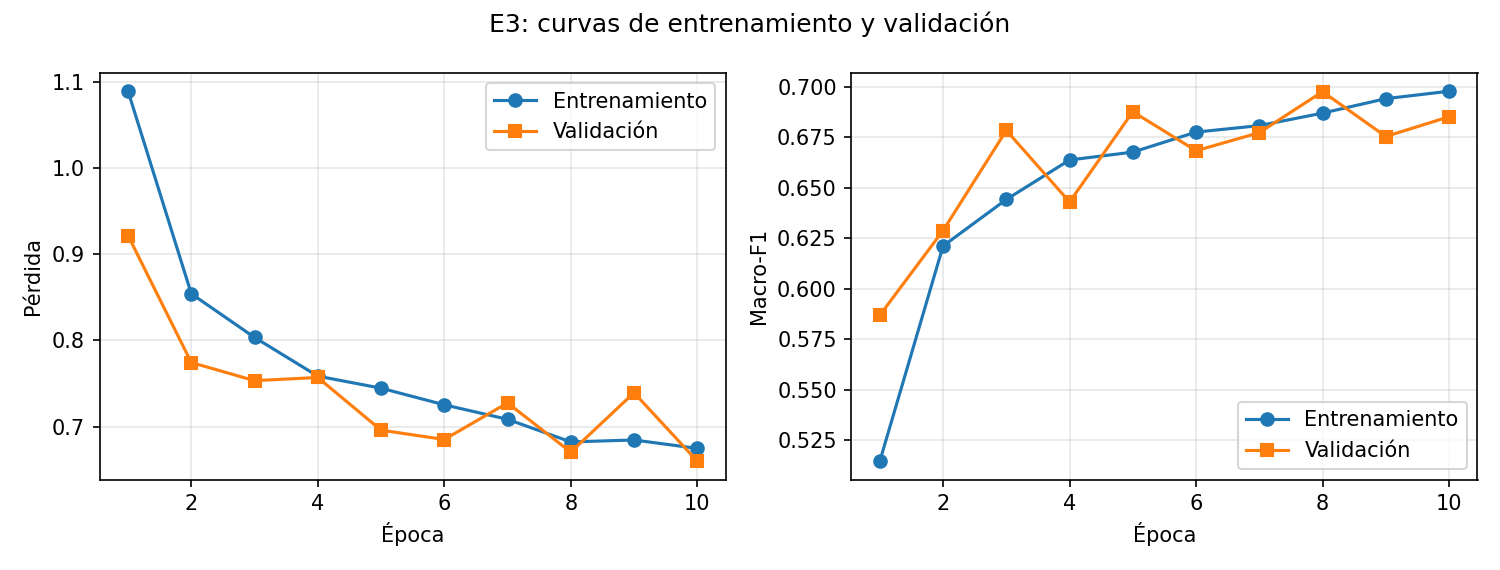

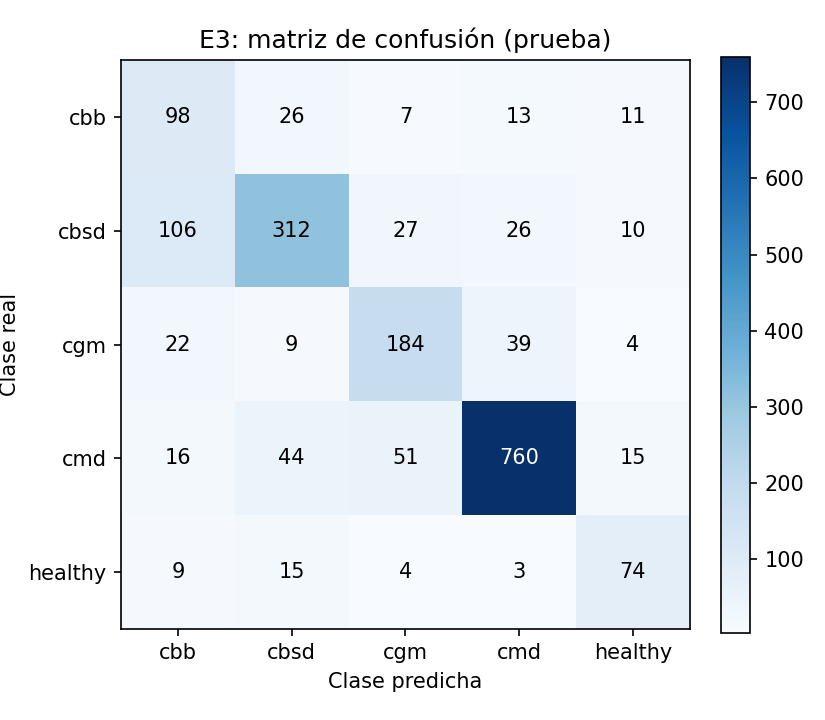

,precision,recall,f1,imagenes
cbb,0.390438,0.632258,0.482759,155.0
cbsd,0.768473,0.648649,0.703495,481.0
cgm,0.673993,0.713178,0.693032,258.0
cmd,0.903686,0.857788,0.880139,886.0
healthy,0.649123,0.704762,0.675799,105.0


In [4]:
display(Mostrar('resultados/E3/curvas.png'))
display(Mostrar('resultados/E3/matriz_confusion.png'))
pd.DataFrame(m3['por_clase']).T

## E2 · Ajuste fino del Backbone A
Parte de los pesos del mejor E1, descongela el último bloque del backbone y entrena con una tasa de aprendizaje 10 veces menor.
**Comparación secundaria: E1 frente a E2.** El costo de E2 incluye el de E1 (tiempo acumulado).

In [5]:
m2 = ejecutar('E2')

[2026-11-18 04:37:23] === E2: Parte de E1; bloque final del backbone A descongelado ===
[2026-11-18 04:37:23] Dispositivo: Tesla T4 | semilla: 42
[2026-11-18 04:37:23] Imágenes: train=5600 val=1877 test=1885
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 192MB/s]


[2026-11-18 04:37:26] Pesos iniciales tomados de checkpoints/E1.pt (mejor época de E1)
[2026-11-18 04:37:26] Parámetros: 11,179,077 totales, 8,396,293 entrenables, 44.75 MB
[2026-11-18 04:38:19] Época  1/5 | train pérdida 0.9079 F1 0.5986 | val pérdida 0.6738 F1 0.6956 acc 0.7677  <- mejor hasta ahora (guardado)
[2026-11-18 04:39:12] Época  2/5 | train pérdida 0.5704 F1 0.7353 | val pérdida 0.6317 F1 0.7211 acc 0.7885  <- mejor hasta ahora (guardado)
[2026-11-18 04:40:04] Época  3/5 | train pérdida 0.3629 F1 0.8353 | val pérdida 0.6112 F1 0.7118 acc 0.7837
[2026-11-18 04:40:58] Época  4/5 | train pérdida 0.2007 F1 0.9027 | val pérdida 0.9121 F1 0.6652 acc 0.6974
[2026-11-18 04:41:49] Época  5/5 | train pérdida 0.0911 F1 0.9565 | val pérdida 0.7259 F1 0.7484 acc 0.8141  <- mejor hasta ahora (guardado)
[2026-11-18 04:42:05] PRUEBA -> accuracy 0.8170 | macro-F1 0.7457 | mejor época 5 | entrenamiento 263 s
[2026-11-18 04:42:05] Resultados guardados en resultados/E2/


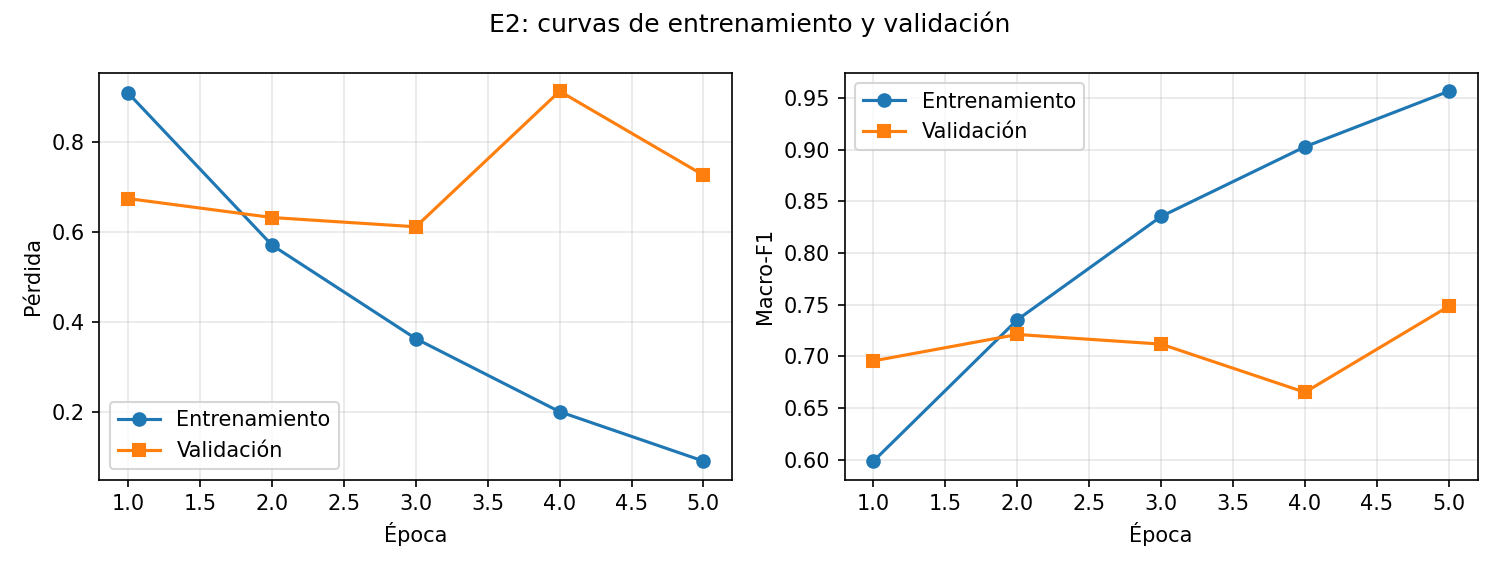

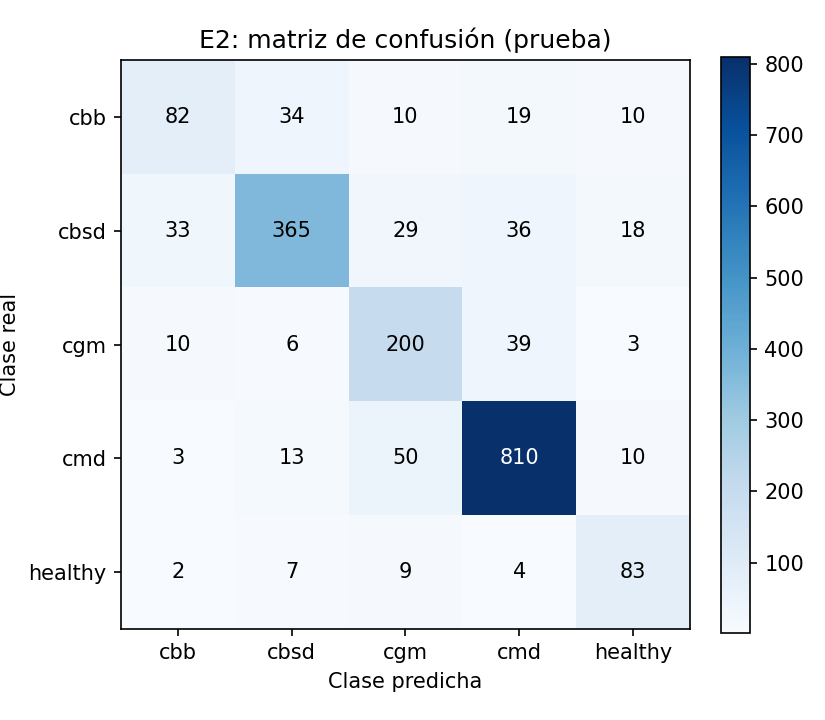

,precision,recall,f1,imagenes
cbb,0.630769,0.529032,0.575439,155.0
cbsd,0.858824,0.758836,0.805740,481.0
cgm,0.671141,0.775194,0.719424,258.0
cmd,0.892070,0.914221,0.903010,886.0
healthy,0.669355,0.790476,0.724891,105.0


In [6]:
display(Mostrar('resultados/E2/curvas.png'))
display(Mostrar('resultados/E2/matriz_confusion.png'))
pd.DataFrame(m2['por_clase']).T

## Tabla consolidada E0–E3

In [7]:
from src import analisis
consolidada = analisis.graficas_comparacion()
consolidada.T

,0,1,2,3
Exp.,E0,E1,E2,E3
Modelo,cnn_pequena,resnet18,resnet18,mobilenet_v2
Accuracy,0.5973,0.7411,0.817,0.7576
Macro-F1,0.4638,0.659,0.7457,0.687
Val macro-F1,0.4532,0.6617,0.7484,0.6975
Mejor época,8,8,5,8
Entren. (s),342.2,539.4,262.9,526.3
Entren. acumulado (s),342.2,539.4,694.8,526.3
Inferencia ms/img (lote 1),0.608,3.849,3.85,5.099
Inferencia ms/img (en lote),0.033,0.858,0.883,0.948


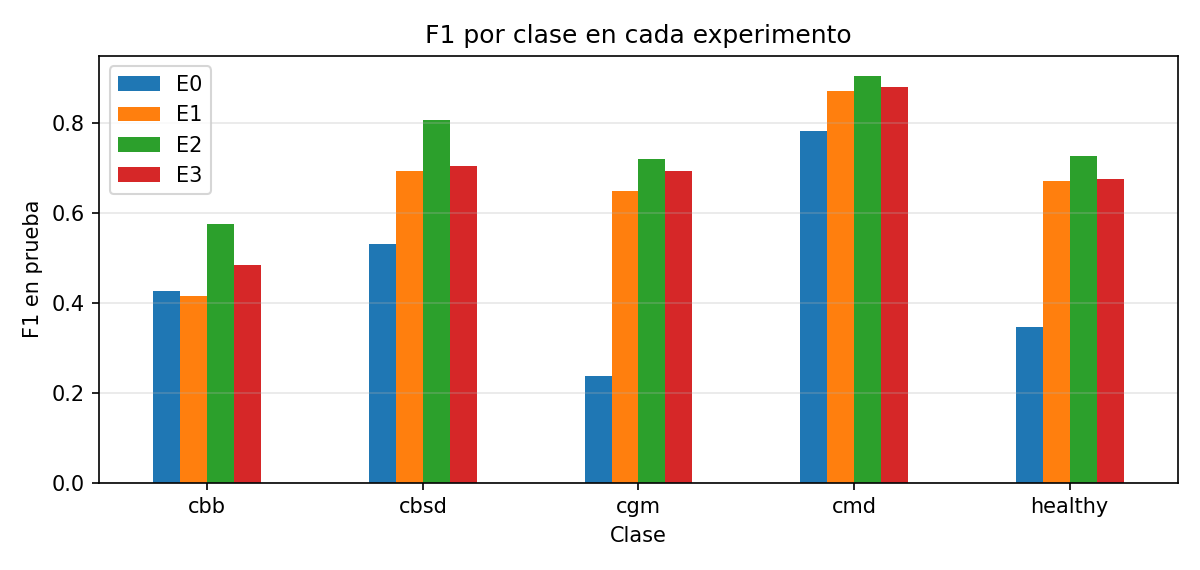

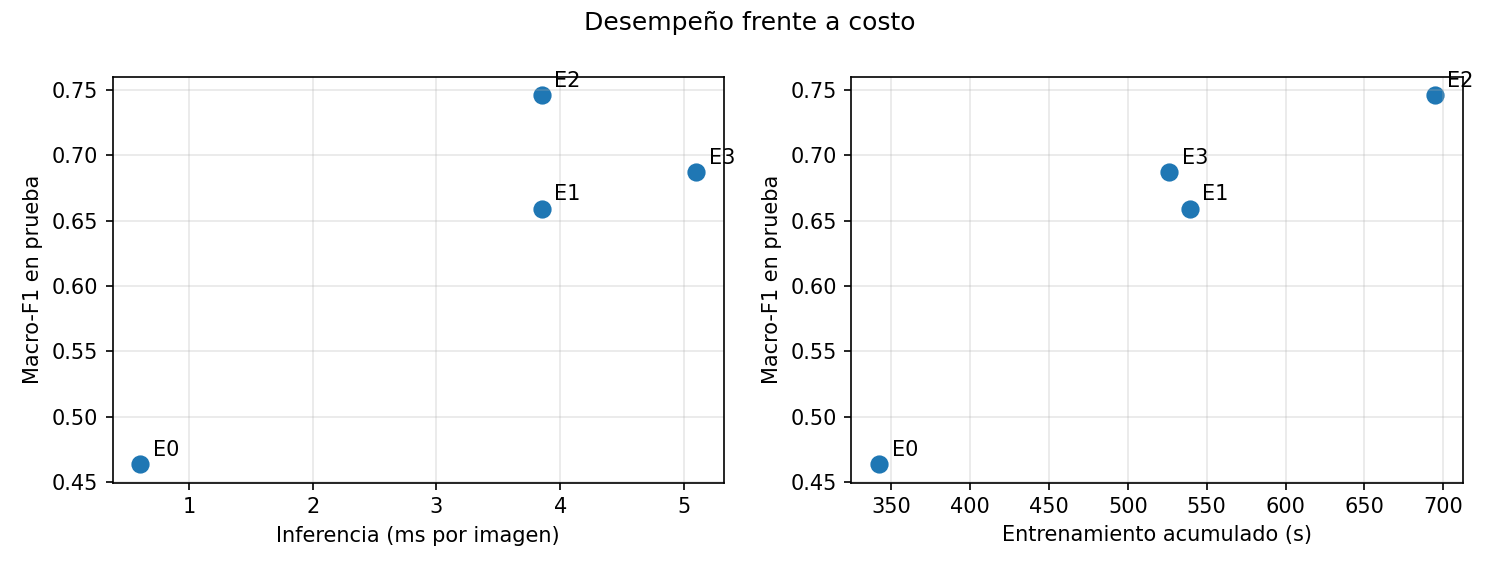

,E0,E1,E2,E3
cbb,0.5032,0.4839,0.5290,0.6323
cbsd,0.4574,0.6383,0.7588,0.6486
cgm,0.1667,0.6783,0.7752,0.7132
cmd,0.8160,0.8646,0.9142,0.8578
healthy,0.5905,0.7048,0.7905,0.7048


In [8]:
display(Mostrar('resultados/comparacion_f1_por_clase.png'))
display(Mostrar('resultados/comparacion_costo.png'))
analisis.tabla_por_clase(metrica='recall')

## Estabilidad (opcional, recomendado)
Repite E1 y E3 con otras semillas para ver cuánto cambian los resultados por azar.
Si la diferencia entre E1 y E3 es menor que esa variación, no se puede afirmar que una arquitectura sea mejor.

In [9]:
SEMILLAS_EXTRA = [1, 2]   # decisión del equipo; cada una repite E1 y E3 completos
for s in SEMILLAS_EXTRA:
    ejecutar('E1', semilla=s)
    ejecutar('E3', semilla=s)
detalle, resumen = analisis.estabilidad()
display(detalle)
resumen

[2026-11-18 04:42:09] === E1_s1: Backbone A congelado, solo cabeza ===
[2026-11-18 04:42:09] Dispositivo: Tesla T4 | semilla: 1
[2026-11-18 04:42:09] Imágenes: train=5600 val=1877 test=1885
[2026-11-18 04:42:10] Parámetros: 11,179,077 totales, 2,565 entrenables, 44.75 MB
[2026-11-18 04:43:01] Época  1/10 | train pérdida 1.2356 F1 0.4582 | val pérdida 1.0206 F1 0.5587 acc 0.6329  <- mejor hasta ahora (guardado)
[2026-11-18 04:43:55] Época  2/10 | train pérdida 0.9900 F1 0.5659 | val pérdida 0.8868 F1 0.6136 acc 0.6867  <- mejor hasta ahora (guardado)
[2026-11-18 04:44:47] Época  3/10 | train pérdida 0.9257 F1 0.5884 | val pérdida 0.8509 F1 0.6007 acc 0.6889
[2026-11-18 04:45:41] Época  4/10 | train pérdida 0.8977 F1 0.5976 | val pérdida 0.8690 F1 0.6078 acc 0.6723
[2026-11-18 04:46:33] Época  5/10 | train pérdida 0.8801 F1 0.6050 | val pérdida 0.7820 F1 0.6225 acc 0.7107  <- mejor hasta ahora (guardado)
[2026-11-18 04:47:26] Época  6/10 | train pérdida 0.8667 F1 0.6174 | val pérdida 0.7

,experimento,ejecucion,macro_f1,accuracy
0,E1,E1,0.658974,0.741114
1,E1,E1_s1,0.643810,0.735809
2,E1,E1_s2,0.660724,0.742706
3,E3,E3,0.687045,0.757560
4,E3,E3_s1,0.681831,0.748541
5,E3,E3_s2,0.672783,0.745889


macro_f1                               accuracy                  \
                mean     std     min     max count     mean     std     min   
experimento                                                                   
E1            0.6545  0.0093  0.6438  0.6607     3   0.7399  0.0036  0.7358   
E3            0.6806  0.0072  0.6728  0.6870     3   0.7507  0.0061  0.7459   

                           
                max count  
experimento                
E1           0.7427     3  
E3           0.7576     3

In [10]:
import pandas as pd, json
from src import analisis
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 30)
print('== TABLA CONSOLIDADA ==')
print(analisis.tabla_consolidada().to_string(index=False))
print('\n== F1 POR CLASE ==')
print(analisis.tabla_por_clase(metrica='f1').to_string())
print('\n== RECALL POR CLASE ==')
print(analisis.tabla_por_clase(metrica='recall').to_string())
detalle, resumen = analisis.estabilidad()
print('\n== ESTABILIDAD (3 semillas) ==')
print(detalle.to_string(index=False))
print(resumen.to_string())
m2 = json.load(open('resultados/E2/metricas.json'))
print('\n== E2 ==  mejor época', m2['mejor_epoca'], '| entrenamiento', m2['tiempo_entrenamiento_s'], 's | acumulado', m2['tiempo_entrenamiento_acumulado_s'], 's | entrenables', m2['parametros_entrenables'])

== TABLA CONSOLIDADA ==
Exp.       Modelo  Accuracy  Macro-F1  Val macro-F1  Mejor época  Entren. (s)  Entren. acumulado (s)  Inferencia ms/img (lote 1)  Inferencia ms/img (en lote)  Parámetros  Entrenables  Tamaño (MB) Dispositivo
  E0  cnn_pequena    0.5973    0.4638        0.4532            8        342.2                  342.2                       0.608                        0.033       24133        24133         0.10    Tesla T4
  E1     resnet18    0.7411    0.6590        0.6617            8        539.4                  539.4                       3.849                        0.858    11179077         2565        44.75    Tesla T4
  E2     resnet18    0.8170    0.7457        0.7484            5        262.9                  694.8                       3.850                        0.883    11179077      8396293        44.75    Tesla T4
  E3 mobilenet_v2    0.7576    0.6870        0.6975            8        526.3                  526.3                       5.099                